In [1]:
import matplotlib
import numpy as np
import pandas as pd
from narwhals import Int64
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.metrics import make_scorer, brier_score_loss
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.metrics import classification_report
from sklearn.model_selection import TunedThresholdClassifierCV, train_test_split
from sklearn.datasets import make_classification
from sklearn.model_selection import cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (f1_score, classification_report, confusion_matrix,
                             roc_auc_score, average_precision_score, brier_score_loss)

In [2]:
train_df = pd.read_csv(r"C:\Users\maggi\CollegeSchoolWork\SDS336_MachineLearning\stop-and-search\data\cleaned_data\stop_search_train1.csv", index_col=0)
test_df = pd.read_csv(r"C:\Users\maggi\CollegeSchoolWork\SDS336_MachineLearning\stop-and-search\data\cleaned_data\stop_search_test1.csv", index_col=0)

In [3]:
train_df.head()

,District,Zone,StopDescription,VehicleYear,VehicleStyle,VehicleColor,SubjectID,SubjectRace,SubjectGender,SubjectAge,...,month,year,weekend,isDriver,isLA,orig_height,orig_weight,BMI,vital_flag,orig_age
FieldInterviewID,,,,,,,,,,,,,,,,,,,,,
522057,2,K,TRAFFIC VIOLATION,1998.0,FOUR DOOR,BLUE,597195,WHITE,0.0,56.0,...,9,2019,1,1,1.0,74.0,210.0,26.959459,0,56.0
464820,3,U,TRAFFIC VIOLATION,2018.0,FOUR DOOR,WHITE,529472,ASIAN,0.0,36.0,...,8,2018,0,1,1.0,66.0,150.0,24.207989,0,36.0
598110,8,C,TRAFFIC VIOLATION,2020.0,FOUR DOOR,GRAY,685380,WHITE,1.0,NaN,...,10,2022,1,0,NaN,NaN,NaN,NaN,0,NaN
456041,6,F,TRAFFIC VIOLATION,2007.0,SPORTS UTILITY,WHITE,519128,BLACK,1.0,69.0,...,6,2018,0,0,NaN,66.0,250.0,40.346648,0,69.0
584726,7,I,TRAFFIC VIOLATION,2014.0,SPORTS UTILITY,GRAY,671150,BLACK,0.0,65.0,...,6,2022,0,1,1.0,62.0,156.0,28.529657,0,65.0


# Preprocessing

In [4]:
# Dropping unnecessary columns for modeling
train_date = train_df["event_dt"]
train_df = train_df.drop(["event_dt", "orig_age", "vital_flag", "orig_height", "orig_weight", "BMI", "year", "Zone", "Latitude", "Longitude", "SubjectID"], axis = 1)

# Dropping unnecessary columns for modeling
test_date = test_df["event_dt"]
test_df = test_df.drop(["event_dt", "orig_age", "vital_flag", "orig_height", "orig_weight", "BMI", "year", "Zone", "Latitude", "Longitude", "SubjectID"], axis = 1)

# Unfloating zip code
train_df["Zip"] = train_df["Zip"].astype("Int64")
test_df["Zip"] = test_df["Zip"].astype("Int64")

# Defining categorical columns
cat_cols = ["SubjectRace", "Zip", "District"]
# Defining discrete/numerical columns
dis_cols = ["SubjectGender", "SubjectAge", "SubjectHeight", "SubjectWeight", "isLA","VehicleYear", "SubjectHasPhotoID", "hour", "night", "isDriver"]
# Numerical columns we would like to scale
scale_cols = ["SubjectAge", "SubjectHeight", "SubjectWeight", "VehicleYear", "hour"]
# Binary columns
bin_cols = ["SubjectGender", "isLA", "SubjectHasPhotoID", "night", "isDriver"]

# Converting variables into strings
train_df[cat_cols] = train_df[cat_cols].astype(str)
# Converting variables into strings
test_df[cat_cols] = test_df[cat_cols].astype(str)

In [5]:
target = "search_occurred"
X_train = train_df.drop([target], axis = 1)[cat_cols + dis_cols]
y_train = train_df[target]
X_test = test_df.drop([target], axis = 1)[cat_cols + dis_cols]
y_test = test_df[target]

### Classes

In [6]:
class CatBinner(BaseEstimator, TransformerMixin):
    def __init__(self, cols, min_freq=0.01, fill_value="Other"):
        self.cols = cols
        self.min_freq = min_freq
        self.fill_value = fill_value

    def fit(self, X, y=None):
        self.keep_labels = {}
        for c in self.cols:
            freq = X[c].value_counts(normalize=True)
            self.keep_labels[c] = freq[freq >= self.min_freq].index.tolist()

        return self

    def transform(self, X):
        X_copy = X.copy()
        for c in self.cols:
            labels = self.keep_labels[c]
            X_copy[c] = np.where(X_copy[c].isin(labels) | X_copy[c].isna(), X_copy[c], self.fill_value)
        return X_copy

    def set_output(self, *, transform=None):
        return self

class RoundImputed(BaseEstimator, TransformerMixin):
    def __init__(self, cols):
        self.cols = cols

    def fit(self, X, y=None):
        rounded = X[self.cols].round()
        self.min_ = rounded.min()
        self.max_ = rounded.max()
        return self

    def transform(self, X):
        X_copy = X.copy()
        X_copy[self.cols] = X_copy[self.cols].round().clip(self.min_, self.max_, axis=1)
        return X_copy

    def set_output(self, *, transform=None):
        return self

class OrdEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols, inner):
        self.cat_cols = cat_cols
        self.inner = inner

    def _encode(self, X):
        X_enc = X.copy()
        X_enc[self.cat_cols] = self.encoder_.transform(X[self.cat_cols])
        return X_enc

    def _decode(self, X_imp):
        X_dec = X_imp.copy()
        X_dec[self.cat_cols] = self.encoder_.inverse_transform(X_imp[self.cat_cols])
        return X_dec

    def fit_transform(self, X, y=None):
        self.encoder_ = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan)
        self.encoder_.fit(X[self.cat_cols])
        self.inner_ = clone(self.inner)
        return self._decode(self.inner_.fit_transform(self._encode(X), y))

    def fit(self, X, y=None):
        self.fit_transform(X, y)
        return self

    def transform(self, X):
        return self._decode(self.inner_.transform(self._encode(X)))

    def set_output(self, *, transform=None):
        return self

In [7]:
def build_pipeline(model, cat_cols, dis_cols, scale_cols):
    imputer = IterativeImputer(estimator=HistGradientBoostingRegressor(max_iter=50, random_state=10), skip_complete=True, max_iter=5, tol=1e-2, random_state=10)

    impute = Pipeline([
        ("imputer", imputer),
        ("round", RoundImputed(cols=cat_cols + dis_cols)),
    ])

    impute.set_output(transform="pandas")

    encode = ColumnTransformer([("encode", OneHotEncoder(handle_unknown="ignore"), cat_cols), ("scale", StandardScaler(), scale_cols)], remainder="passthrough", verbose_feature_names_out=False)

    pipeline = Pipeline([
        ("bin", CatBinner(cols=cat_cols, min_freq=0.01, fill_value="Other")),
        ("imputer", OrdEncoder(cat_cols, impute)),
        ("encode", encode),
        ("model", model)
    ], memory="cache_dir")

    return pipeline

# Modeling

In [8]:
# building pipeline using best parameters found in hyperparameter tuning script
lr = LogisticRegression(l1_ratio=1, C = 0.012742749857031334, max_iter = 1000, random_state=10, solver="saga")

pipeline = build_pipeline(lr, cat_cols, bin_cols, scale_cols)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=10)

oof_probs = cross_val_predict(pipeline, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

# Calibration

### Pre-Calibration results

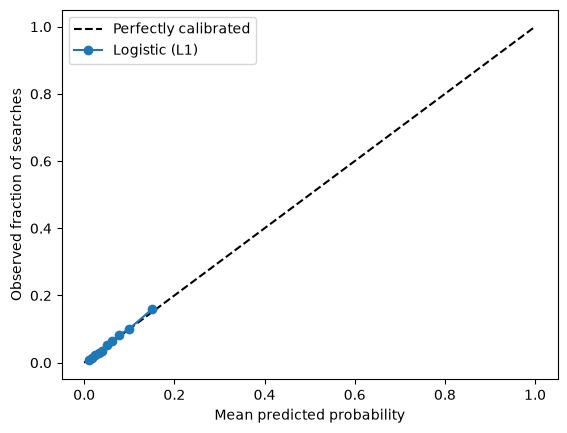

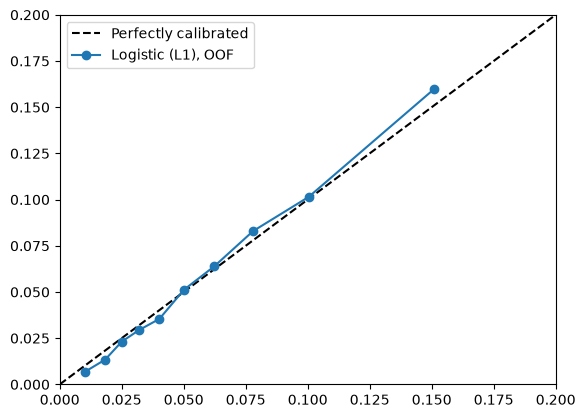

OOF Brier score: 0.05145835123110301


In [9]:
prob_true, prob_pred = calibration_curve(y_train, oof_probs, n_bins=10, strategy="quantile")

plt.plot([0, 1], [0, 1], "k--", label="Perfectly calibrated")
plt.plot(prob_pred, prob_true, marker="o", label="Logistic (L1)")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed fraction of searches")
plt.legend()
plt.show()

plt.plot([0, 0.2], [0, 0.2], "k--", label="Perfectly calibrated")
plt.plot(prob_pred, prob_true, marker="o", label="Logistic (L1), OOF")
plt.xlim(0, 0.2); plt.ylim(0, 0.2)
plt.legend()
plt.show()

print("OOF Brier score:", brier_score_loss(y_train, oof_probs))


In [10]:
train_df['search_occurred'].value_counts()

search_occurred
0    128583
1      7738
Name: count, dtype: int64

In [11]:
bs = brier_score_loss(y_train, oof_probs)
bs_ref = brier_score_loss(y_train, np.full(len(y_train), y_train.mean()))
print("Brier skill score:", 1 - bs / bs_ref)

Brier skill score: 0.03889881239886528


### Breakdown of calibration plot by variable

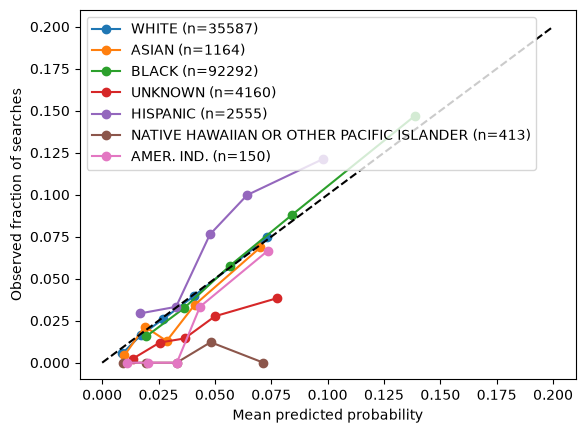

In [12]:
# SubjectRace
y_arr = y_train.to_numpy()
race = X_train["SubjectRace"].to_numpy()

for g in pd.unique(race):
    mask = race == g
    n = mask.sum()
    pt, pp = calibration_curve(y_arr[mask], oof_probs[mask], n_bins=5, strategy="quantile")
    plt.plot(pp, pt, marker="o", label=f"{g} (n={n})")

plt.plot([0, 0.2], [0, 0.2], "k--")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed fraction of searches")
plt.legend()
plt.show()

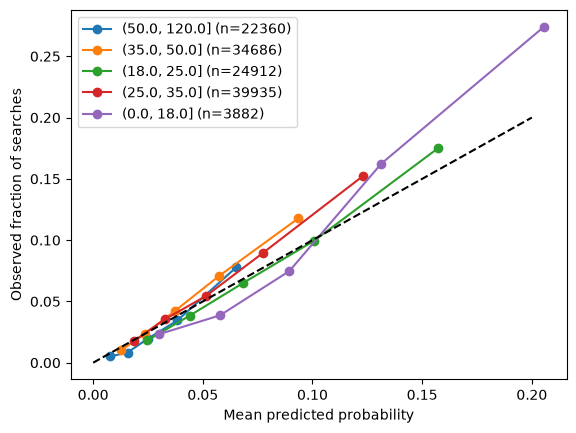

In [13]:
# SubjectAge
y_arr = y_train.to_numpy()
age_band = pd.cut(X_train["SubjectAge"], bins=[0, 18, 25, 35, 50, 120]).astype(str).to_numpy()

for g in pd.unique(age_band):
    mask = age_band == g
    n = mask.sum()
    if n < 1:   # skip tiny groups; adjust to your data
        continue
    pt, pp = calibration_curve(y_arr[mask], oof_probs[mask], n_bins=5, strategy="quantile")
    plt.plot(pp, pt, marker="o", label=f"{g} (n={n})")

plt.plot([0, 0.2], [0, 0.2], "k--")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed fraction of searches")
plt.legend()
plt.show()

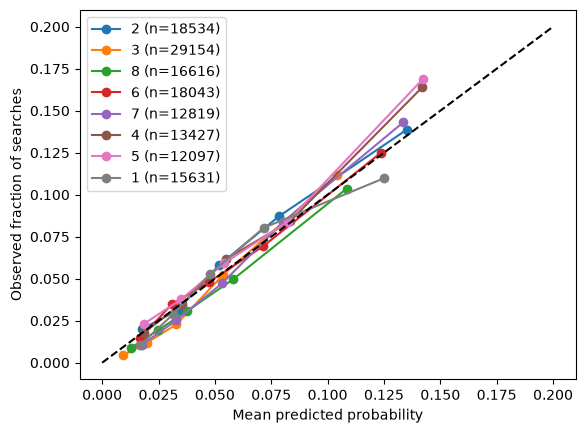

In [14]:
# District
y_arr = y_train.to_numpy()
district = X_train["District"].to_numpy()

for g in pd.unique(district):
    mask = district == g
    n = mask.sum()
    pt, pp = calibration_curve(y_arr[mask], oof_probs[mask], n_bins=5, strategy="quantile")
    plt.plot(pp, pt, marker="o", label=f"{g} (n={n})")

plt.plot([0, 0.2], [0, 0.2], "k--")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed fraction of searches")
plt.legend()
plt.show()

### Calibration

In [15]:
from sklearn.isotonic import IsotonicRegression

y_arr = y_train.to_numpy()

def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

# Platt-style (fits slope and intercept on the logit scale)
platt = cross_val_predict(LogisticRegression(C=1e6), logit(oof_probs), y_arr,
                          cv=cv, method="predict_proba")[:, 1]

# Isotonic
iso = np.zeros(len(oof_probs))
for tr, te in cv.split(oof_probs, y_arr):
    m = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(oof_probs[tr], y_arr[tr])
    iso[te] = m.predict(oof_probs[te])

ref = brier_score_loss(y_arr, np.full(len(y_arr), y_arr.mean()))
for name, p in [("raw", oof_probs), ("platt", platt), ("isotonic", iso)]:
    b = brier_score_loss(y_arr, p)
    print(name, b, "BSS:", 1 - b / ref)

raw 0.05145835123110301 BSS: 0.03889881239886528
platt 0.05145645001727563 BSS: 0.038934321870577104
isotonic 0.05148609219104881 BSS: 0.038380687178930284


Because brier scores are very similar across both recalibrations, we will use platt since it fits only two parameters, so it’s stable when positives are rare like in our dataset (~5.5% of stops), and it keeps the probabilities strictly ordered, whereas isotonic’s step function can overfit in sparse regions of the probability range

In [16]:
# Final calibrator, fit on all out-of-fold predictions, used for the test set
platt_final = LogisticRegression(C=1e6).fit(logit(oof_probs), y_arr)
print("Platt slope:", platt_final.coef_[0][0], "| intercept:", platt_final.intercept_[0])

Platt slope: 1.1087382520983295 | intercept: 0.27631635450224884


# Threshold Tuning

In [17]:
tuned = TunedThresholdClassifierCV(pipeline, scoring="f1", cv=cv, thresholds=100, refit=True)
tuned.fit(X_train, y_train)

cal_thr = platt_final.predict_proba(logit(np.array([tuned.best_threshold_])))[:, 1][0]

print("Best threshold:", tuned.best_threshold_)
print("CV score at that threshold:", tuned.best_score_)

C:\Users\maggi\anaconda3\envs\SDS336_MachineLearning\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
C:\Users\maggi\anaconda3\envs\SDS336_MachineLearning\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
C:\Users\maggi\anaconda3\envs\SDS336_MachineLearning\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
C:\Users\maggi\anaconda3\envs\SDS336_MachineLearning\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


Best threshold: 0.10140586224134494
CV score at that threshold: 0.20670997118801543


# Test Set Results

raw: Brier=0.05145  BSS=0.0389
calibrated: Brier=0.05147  BSS=0.0384
test slope: 0.9860863911440153 intercept: -0.035394030362403905


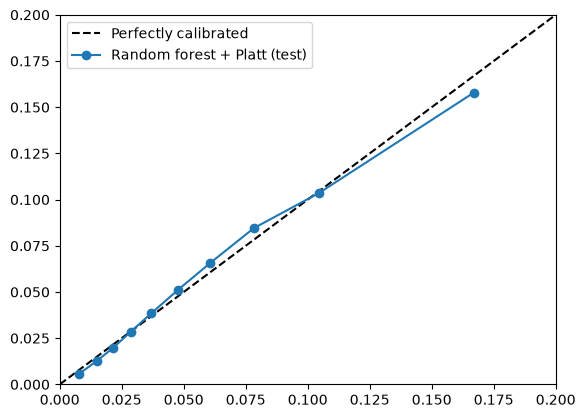

ROC AUC: 0.7329475420065702
Average precision: 0.13188947094826797
              precision    recall  f1-score   support

           0       0.96      0.87      0.91     32147
           1       0.14      0.37      0.21      1934

    accuracy                           0.84     34081
   macro avg       0.55      0.62      0.56     34081
weighted avg       0.91      0.84      0.87     34081

[[27879  4268]
 [ 1221   713]]


In [18]:
y_t = y_test.to_numpy()
test_raw = tuned.estimator_.predict_proba(X_test)[:, 1]
test_cal = platt_final.predict_proba(logit(test_raw))[:, 1]

# 1. Probability quality (raw vs calibrated)
ref = brier_score_loss(y_t, np.full(len(y_t), y_train.mean()))
for name, p in [("raw", test_raw), ("calibrated", test_cal)]:
    b = brier_score_loss(y_t, p)
    print(f"{name}: Brier={b:.5f}  BSS={1 - b/ref:.4f}")

# 2. Calibration slope and intercept on the test set
cal = LogisticRegression(C=1e6).fit(logit(test_cal), y_t)
print("test slope:", cal.coef_[0][0], "intercept:", cal.intercept_[0])   # ideal: ~1 and ~0

# 3. Calibration curve
pt, pp = calibration_curve(y_t, test_cal, n_bins=10, strategy="quantile")
plt.plot([0, 0.2], [0, 0.2], "k--", label="Perfectly calibrated")
plt.plot(pp, pt, marker="o", label="Logistic Regression + Platt (test)")
plt.xlim(0, 0.2); plt.ylim(0, 0.2); plt.legend(); plt.show()

# 4. Ranking metrics (same for raw and calibrated)
print("ROC AUC:", roc_auc_score(y_t, test_cal))
print("Average precision:", average_precision_score(y_t, test_cal))

# 5. Classification at the tuned threshold (same stops as your current report)
y_pred = (test_cal >= cal_thr).astype(int)
print(classification_report(y_t, y_pred))
print(confusion_matrix(y_t, y_pred))